# The Path Less Travelled

This notebook will contain all the driving code for my honours project including synthetic data generation, real data preprocessing, model training, and evaluation. 

In [1]:
from wanderer import *
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#load the OUP process from json
OUP_process = StochasticProcess.from_json('OUP_process_EM_orig.json')

In [3]:
#Fourier decomp the OUP
coeffs_fourier = fourierDecomposition(1000, OUP_process)

#KL decomp the OUP
coeffs_KL, eigenfuncs_KL, eigenvals_KL = KLDecomposition(process = OUP_process, num_components=1000, )

In [5]:


#create storage for integrated errors for abs and square for both Fourier and KL decompositions
avg_errors_abs_Fourier = np.zeros(1000)
avg_errors_square_Fourier = np.zeros(1000)
avg_errors_abs_KL = np.zeros(1000)
avg_errors_square_KL = np.zeros(1000)

center = (coeffs_fourier.shape[1] - 1) // 2


#loop through coefficeitn counts reconstruct process and calculate average errors
for i in range(1, 1001):

    half = i                      # i IS |n|, no division
    lo = max(center - half, 0)
    hi = min(center + half + 1, coeffs_fourier.shape[1])
    
    #reconstruct the process using the first i coefficients for Fourier
    OUP_reconstructed_process_Fourier = reconstructFromFourier(coeffs_fourier[:,lo:hi], OUP_process.timeGrid,OUP_process.timeHorizon)

    #reconstruct the process using the first i coefficients for KL
    OUP_reconstructed_process_KL = reconstructFromKL(coeffs_KL[:,:i], eigenfuncs_KL[:,:i], OUP_process.timeGrid, OUP_process.timeHorizon)

    #calculate the average absolute error for Fourier
    avg_errors_abs_Fourier[i-1] = np.mean(np.abs(OUP_reconstructed_process_Fourier.paths - OUP_process.paths))

    #calculate the average absolute error for KL
    avg_errors_abs_KL[i-1] = np.mean(np.abs(OUP_reconstructed_process_KL.paths - OUP_process.paths))

    #calculate the average square error for Fourier
    avg_errors_square_Fourier[i-1] = np.mean((OUP_reconstructed_process_Fourier.paths - OUP_process.paths)**2)

    #calculate the average square error for KL
    avg_errors_square_KL[i-1] = np.mean((OUP_reconstructed_process_KL.paths - OUP_process.paths)**2)


In [6]:
#print sizes 
print("Size of avg_errors_abs_Fourier:", avg_errors_abs_Fourier.shape)
print("Size of avg_errors_abs_KL:", avg_errors_abs_KL.shape)
print("Size of avg_errors_square_KL:", avg_errors_square_KL.shape)
print("Size of avg_errors_square_Fourier:", avg_errors_square_Fourier.shape)



Size of avg_errors_abs_Fourier: (1000,)
Size of avg_errors_abs_KL: (1000,)
Size of avg_errors_square_KL: (1000,)
Size of avg_errors_square_Fourier: (1000,)


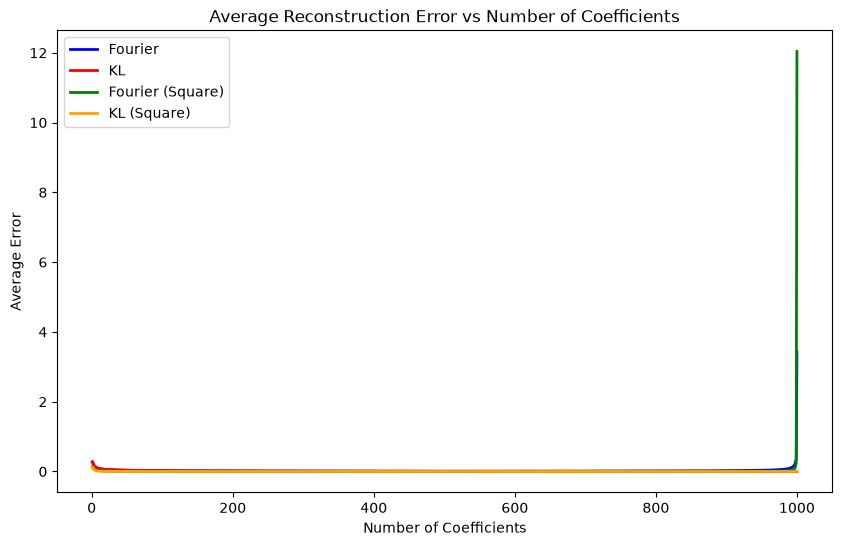

In [7]:
#Plot the abs and square errors as the number of coefficients increases for Fourier and KL
plt.figure(figsize=(10, 6))
plt.plot(range(1, 1001), avg_errors_abs_Fourier, color='blue', linewidth=2, label='Fourier')
plt.plot(range(1, 1001), avg_errors_abs_KL, color='red', linewidth=2, label='KL')
plt.plot(range(1, 1001), avg_errors_square_Fourier, color='green', linewidth=2, label='Fourier (Square)')
plt.plot(range(1, 1001), avg_errors_square_KL, color='orange', linewidth=2, label='KL (Square)')

plt.title('Average Reconstruction Error vs Number of Coefficients')
plt.xlabel('Number of Coefficients')
plt.ylabel('Average Error')
plt.legend()

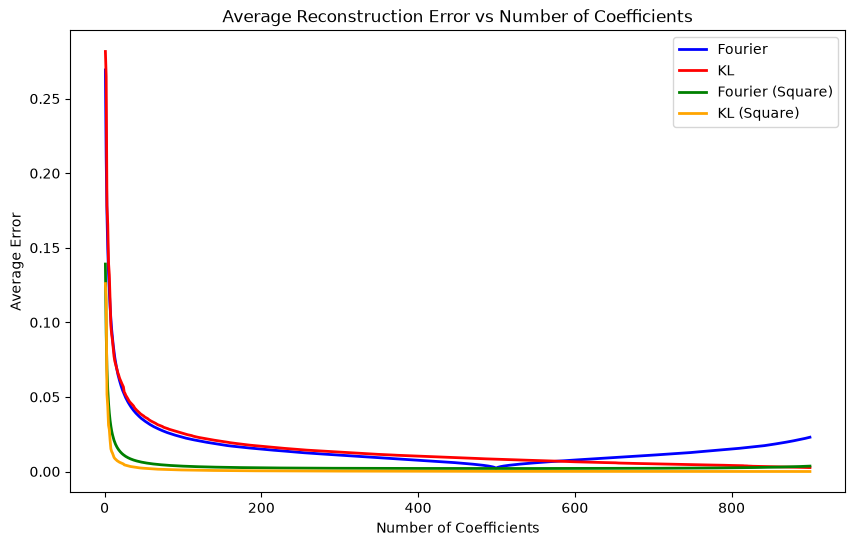

In [8]:
#Plot the abs and square errors as the number of coefficients increases for Fourier and KL excluding last 100
plt.figure(figsize=(10, 6))
plt.plot(range(1, 901), avg_errors_abs_Fourier[:-100], color='blue', linewidth=2, label='Fourier')
plt.plot(range(1, 901), avg_errors_abs_KL[:-100], color='red', linewidth=2, label='KL')
plt.plot(range(1, 901), avg_errors_square_Fourier[:-100], color='green', linewidth=2, label='Fourier (Square)')
plt.plot(range(1, 901), avg_errors_square_KL[:-100], color='orange', linewidth=2, label='KL (Square)')

plt.title('Average Reconstruction Error vs Number of Coefficients')
plt.xlabel('Number of Coefficients')
plt.ylabel('Average Error')
plt.legend()

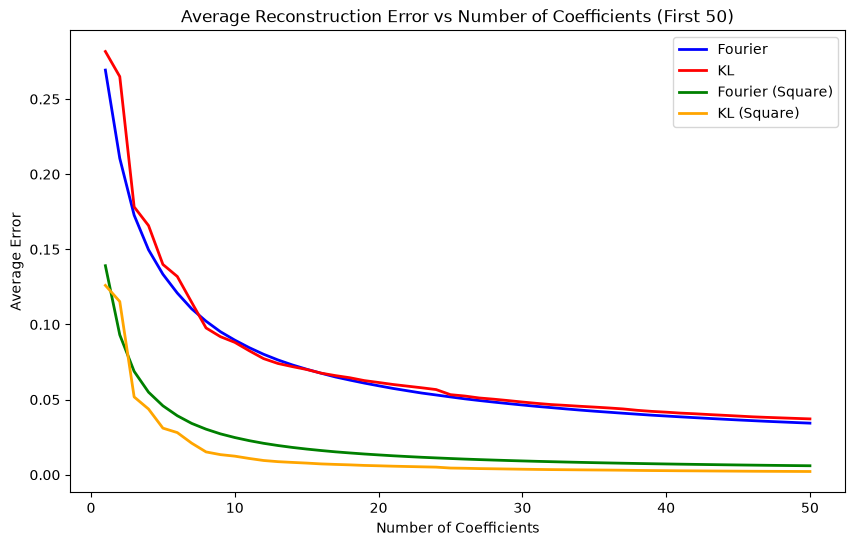

In [9]:
#plot errors for only the first 50 coefficeints for Fourier and KL
plt.figure(figsize=(10, 6))
plt.plot(range(1, 51), avg_errors_abs_Fourier[:50], color='blue', linewidth=2, label='Fourier')
plt.plot(range(1, 51), avg_errors_abs_KL[:50], color='red', linewidth=2, label='KL')
plt.plot(range(1, 51), avg_errors_square_Fourier[:50], color='green', linewidth=2, label='Fourier (Square)')
plt.plot(range(1, 51), avg_errors_square_KL[:50], color='orange', linewidth=2, label='KL (Square)')
plt.title('Average Reconstruction Error vs Number of Coefficients (First 50)')
plt.xlabel('Number of Coefficients')
plt.ylabel('Average Error')
plt.legend()

In [10]:
#save vectors to csv
import pandas as pd

df = pd.DataFrame({
    'Fourier_Abs': avg_errors_abs_Fourier,
    'KL_Abs': avg_errors_abs_KL,
    'Fourier_Square': avg_errors_square_Fourier,
    'KL_Square': avg_errors_square_KL
})

df.to_csv('reconstruction_errors.csv', index=False)